In [1]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import numpy as np
import pandas as pd
import scanpy as sc

sc.set_figure_params(figsize=(4, 4))

In [2]:
def patient_embedding(
    adata, 
    embedding, 
    shape_column, 
    color_column, 
    palette='tab10', 
    order=None
):
    """
    Plots an embedding with different shapes and colors for categories in specified columns,
    using seaborn scatterplot for simplicity.

    Parameters
    ----------
    adata : AnnData
        An AnnData object with embedding coordinates computed.
    embedding : str
        Key in adata.obsm to use for the embedding coordinates.
    shape_column : str
        Column name in adata.obs for categorical values to determine shapes.
    color_column : str
        Column name in adata.obs for categorical values to determine colors.
    palette : str or list, optional
        Color palette for coloring categories.
    order : list, optional
        Specific order of the categories in color_column (affects color mapping and legend order).
    """
    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt

    if embedding not in adata.obsm:
        raise ValueError(f"{embedding} coordinates not found in adata. Run the computation first.")

    # Extract embedding coordinates and categorical annotations
    embedding_df = pd.DataFrame(
        adata.obsm[embedding], columns=[f'{embedding}_1', f'{embedding}_2']
    )
    embedding_df[shape_column] = adata.obs[shape_column].values
    embedding_df[color_column] = adata.obs[color_column].values

    # If order is specified, set categorical type
    if order is not None:
        embedding_df[color_column] = pd.Categorical(embedding_df[color_column], categories=order, ordered=True)

    # Plot
    plt.figure(figsize=(5, 6))
    sns.scatterplot(
        x=f'{embedding}_1',
        y=f'{embedding}_2',
        hue=color_column,
        style=shape_column,
        data=embedding_df,
        palette=palette,
        s=100,
        hue_order=order
    )

    # Beautify plot
    ax = plt.gca()
    ax.grid(False)
    for side in ["top", "right", "bottom", "left"]:
        ax.spines[side].set_visible(False)
    plt.xticks([])
    plt.yticks([])
    plt.xlabel('')
    plt.ylabel('')
    plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
    plt.show()


In [3]:
def plot_tile(anndata, main_category, y_columns):
    """
    Creates a tile plot from an Anndata object with each unique observation
    of y_columns as a unique y-tick, summing the values for each unique y_columns
    category and the main_category.

    Parameters:
    anndata (Anndata): An Anndata object.
    main_category (str): The column name in anndata.obs for the main category.
    y_columns (list): List of categorical column names in anndata.obs to plot on the y-axis.
    """
    # Extract the relevant data
    data = anndata.obs[[main_category] + y_columns]

    # Create a DataFrame to store the summed values
    summed_values = pd.DataFrame()

    # Iterate over each column and sum the values for each category in y_columns
    for col in y_columns:
        # Sum the occurrences of each category in this column for each main_category
        sums = data.groupby([main_category, col]).size().unstack(fill_value=0)
        #sums = sums.rename(lambda x: f"{col}_{x}", axis='columns')
        summed_values = pd.concat([summed_values, sums], axis=1)

    # Sum across all y_columns for each main_category
    summed_values = summed_values.groupby(level=0, axis=1).sum()

    # Plotting
    plt.figure(figsize=(4, 5))
    sns.heatmap(summed_values.transpose(), annot=True, fmt="d", linewidths=.5, cmap='Reds')
    plt.grid(False)
    plt.title('')
    plt.xlabel('Patient Cluster')
    plt.ylabel('')
    plt.show()

In [2]:
adata = sc.read_h5ad("/work/uv525372/heart_atlas/PanPy_analysis/PanPy_Heart_Donor_Annotation.h5ad")

In [22]:
adata.obs["Condition"] = adata.obs["Condition2"]
adata.obs["Condition"] = adata.obs["Condition"].cat.rename_categories({"myocardial infarction": "Acute MI"})
adata.obs["Condition"] = adata.obs["Condition"].cat.rename_categories({"Long-term ischemic": "Post MI"})
adata.obs["Condition"] = adata.obs.apply(lambda row: f"{row['Ischemia']}" if row['Condition'] == 'MI' else row['Condition'], axis=1)

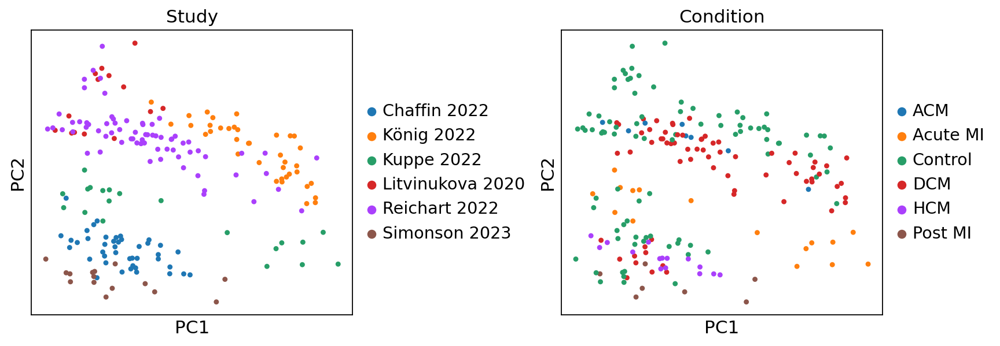

In [24]:
sc.pl.pca(adata, color=["Study", "Condition"], size=64, wspace=0.5)

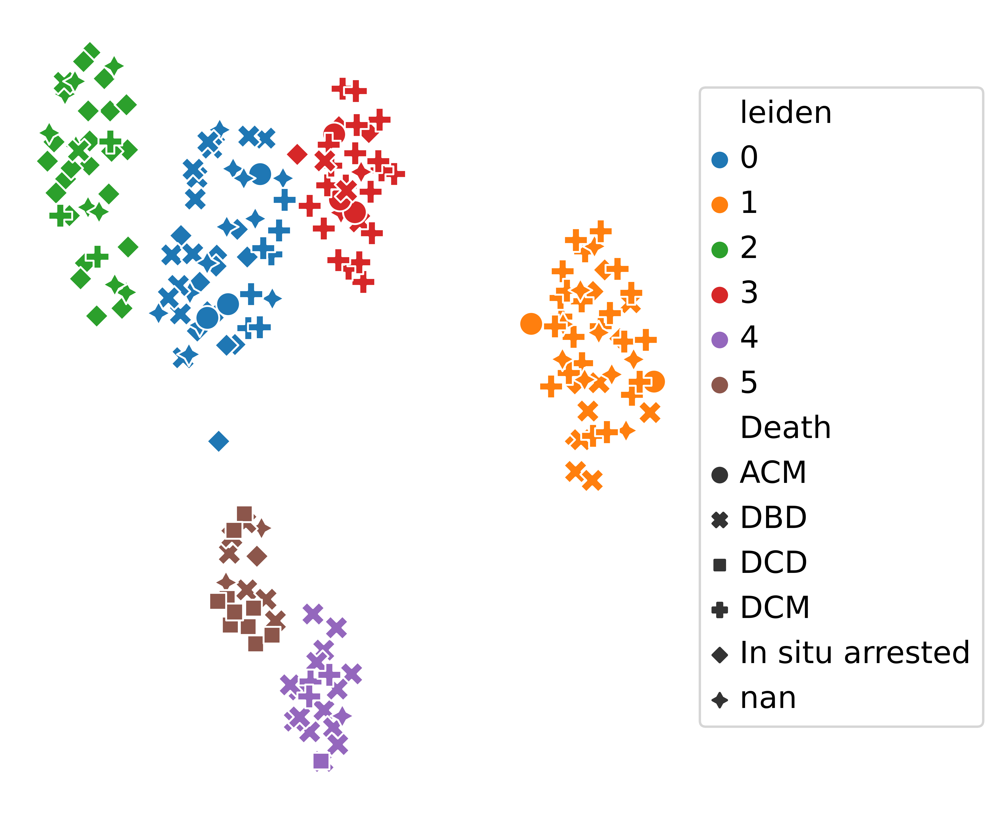

In [101]:
patient_embedding(adata, embedding="X_umap", shape_column='Death', color_column='leiden')

In [102]:
cell_dict = {'CTRL_1': ['0'], 'HF_1': ['1'], 'HF_2': ['2'], 'HF_3':["3"],
             'CTRL_2': ['4'], 'CTRL_3': ['5'],}
adata.obs['Patient_Cluster'] = np.nan
for i in cell_dict.keys():
    ind = pd.Series(adata.obs.leiden).isin(cell_dict[i])
    adata.obs.loc[ind,'Patient_Cluster'] = i

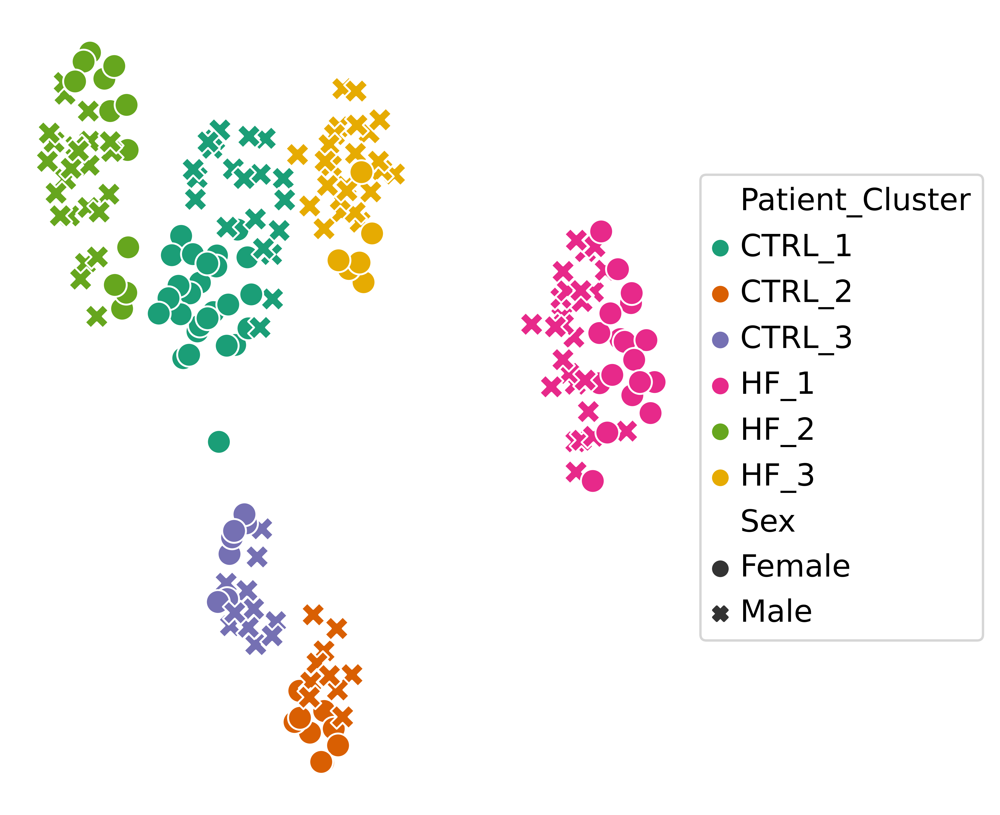

In [103]:
adata = adata[~adata.obs["Age"].isin(['0-9', '10-19']), :]
patient_embedding(adata, embedding="X_umap", shape_column='Sex', order=["CTRL_1", "CTRL_2", "CTRL_3", "HF_1", "HF_2", "HF_3"],color_column='Patient_Cluster', palette="Dark2")

In [ ]:
sc.set_figure_params(scanpy=True, dpi=400)#, #dpi_save=4000)
adata.obs["Myeloid"] = adata.obs["Monocytes"]
sc.pl.umap(adata, color=['Myeloid'], size=85, cmap="Reds")

In [18]:
sc.pl.umap(
    adata,
    color=["leiden", "Condition", "Sex", "Genotype"],
    frameon=False,
    ncols=1, size=40,
)

/home/uv525372/miniconda3/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/uv525372/miniconda3/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/uv525372/miniconda3/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/uv525372/miniconda3/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


/w0/tmp/slurm_uv525372.57037038/ipykernel_178908/4051807502.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["Myeloid"] = adata.obs["Monocytes"]


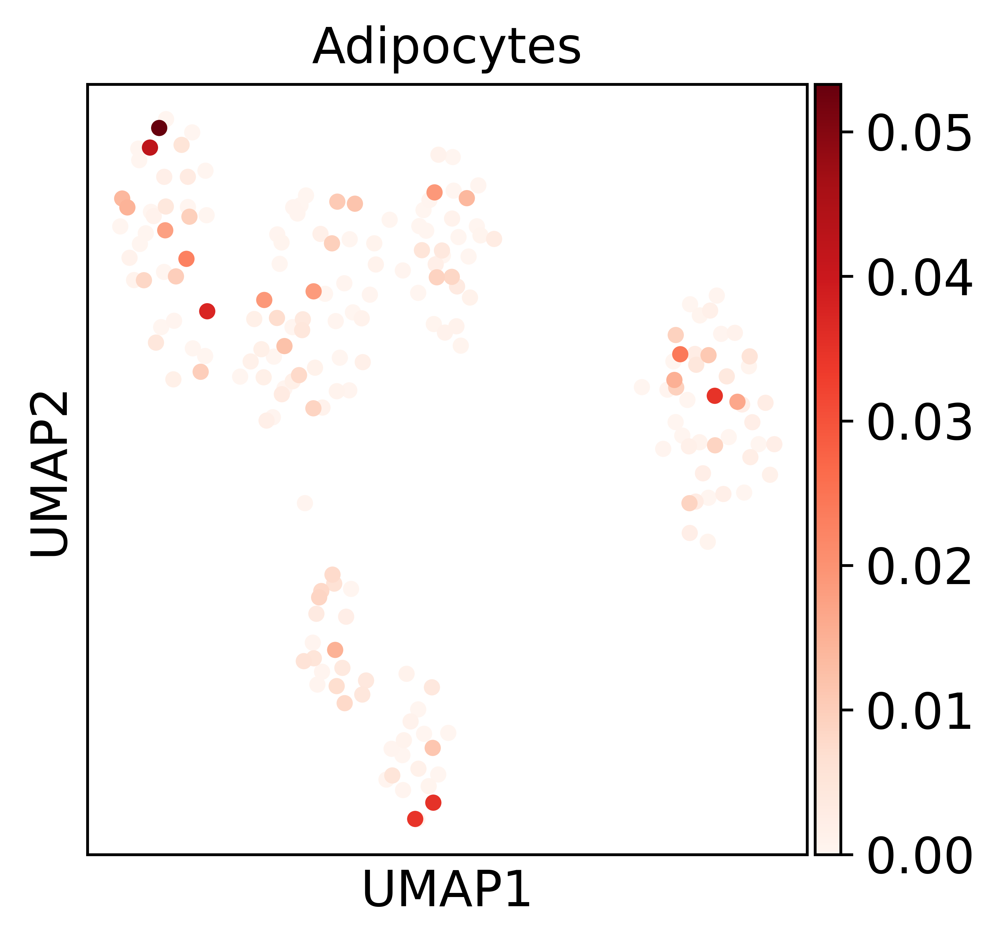

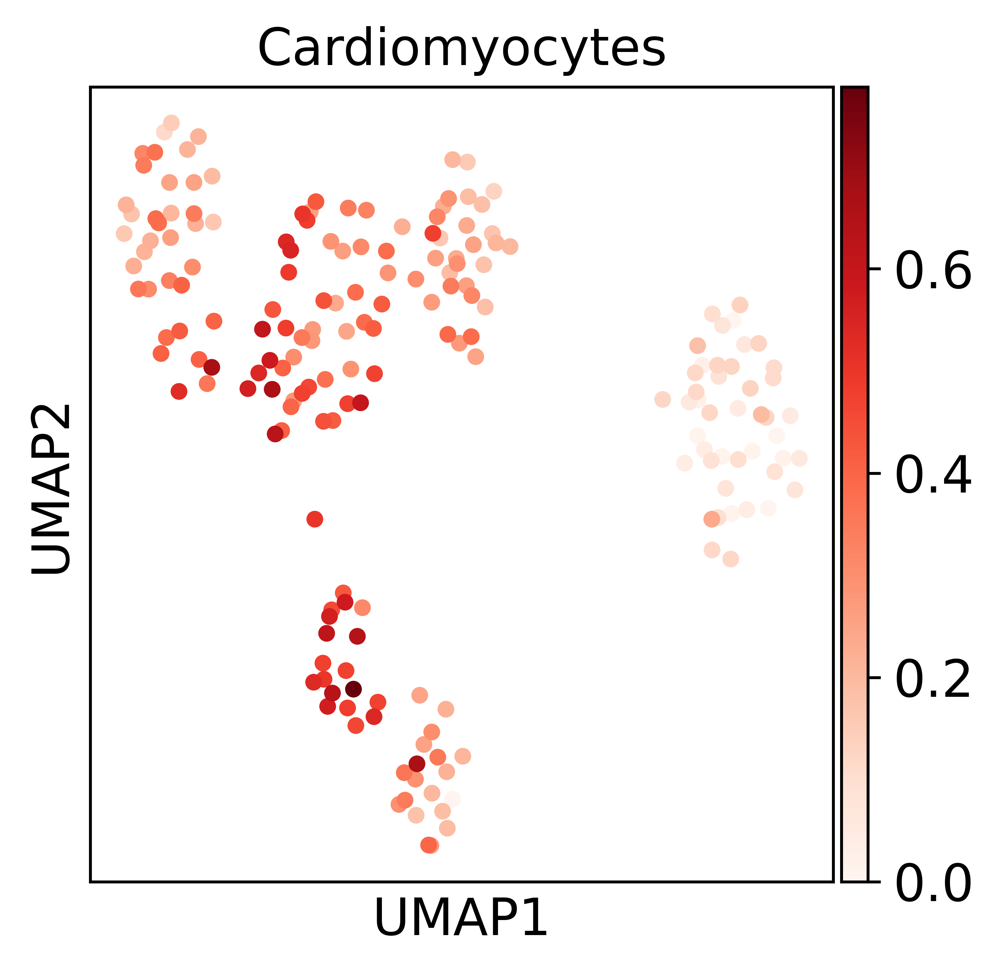

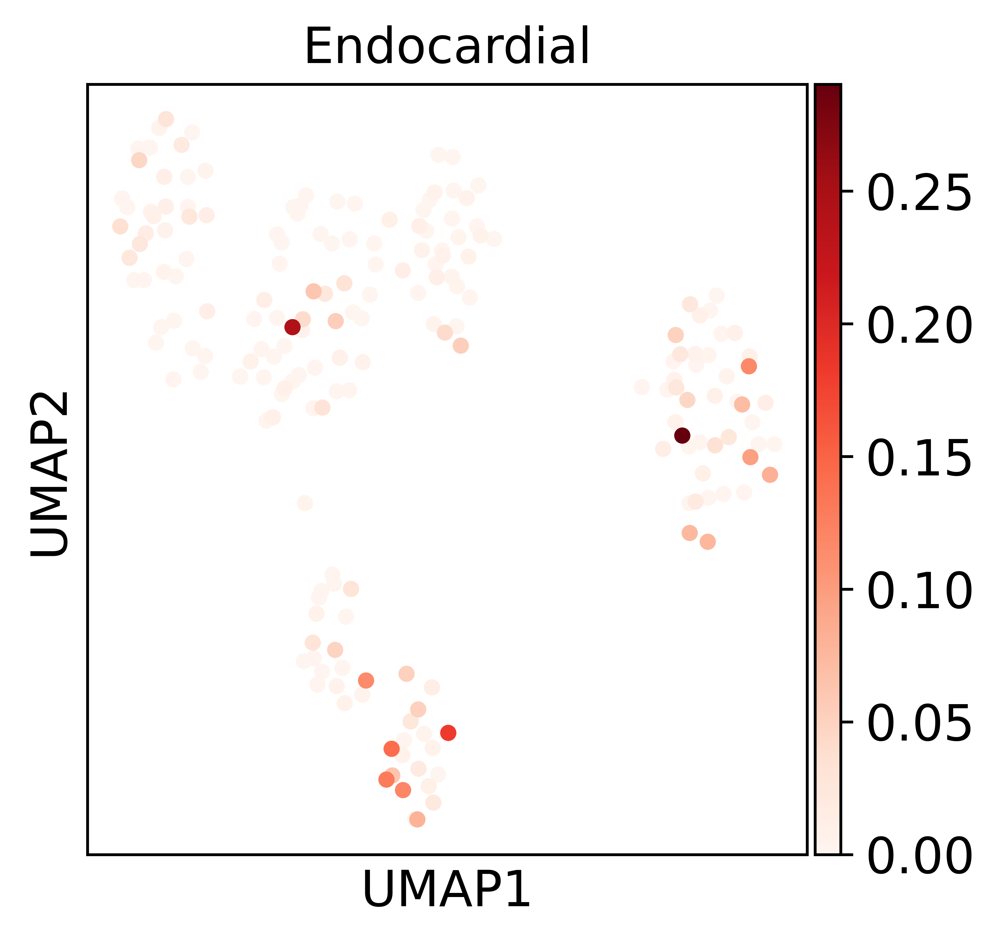

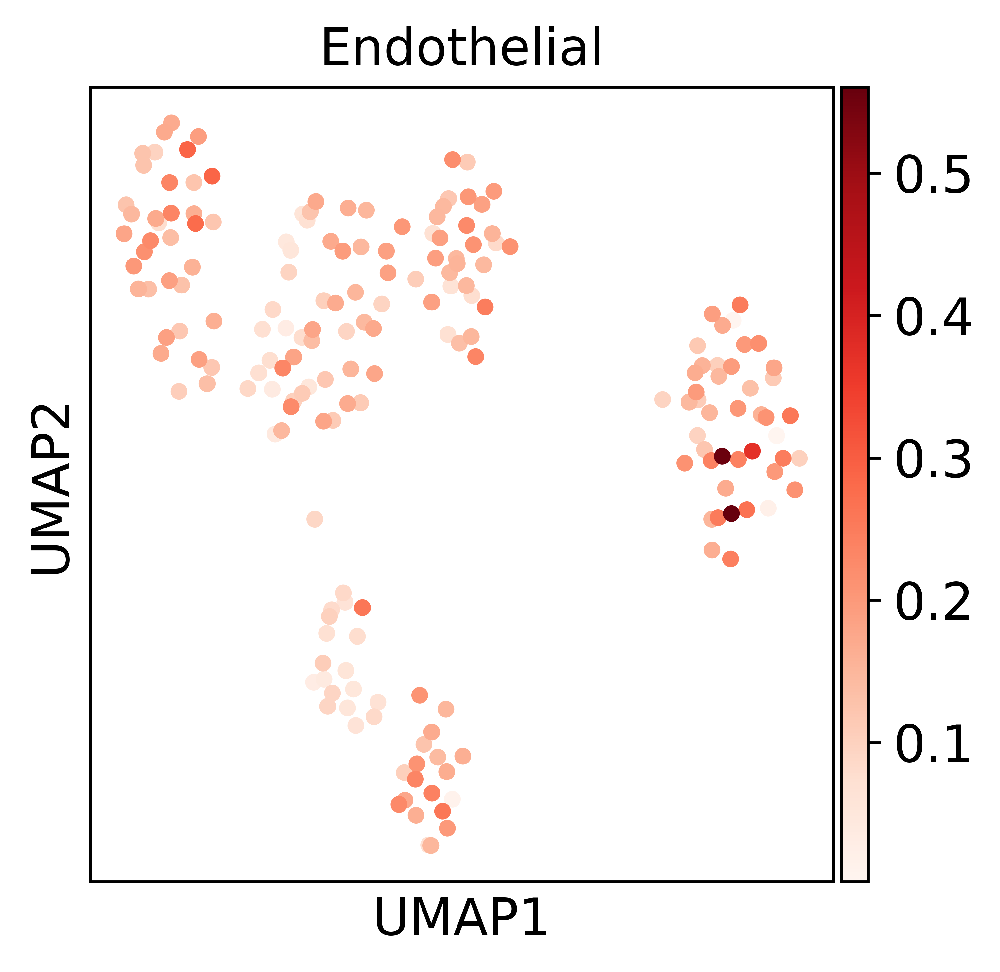

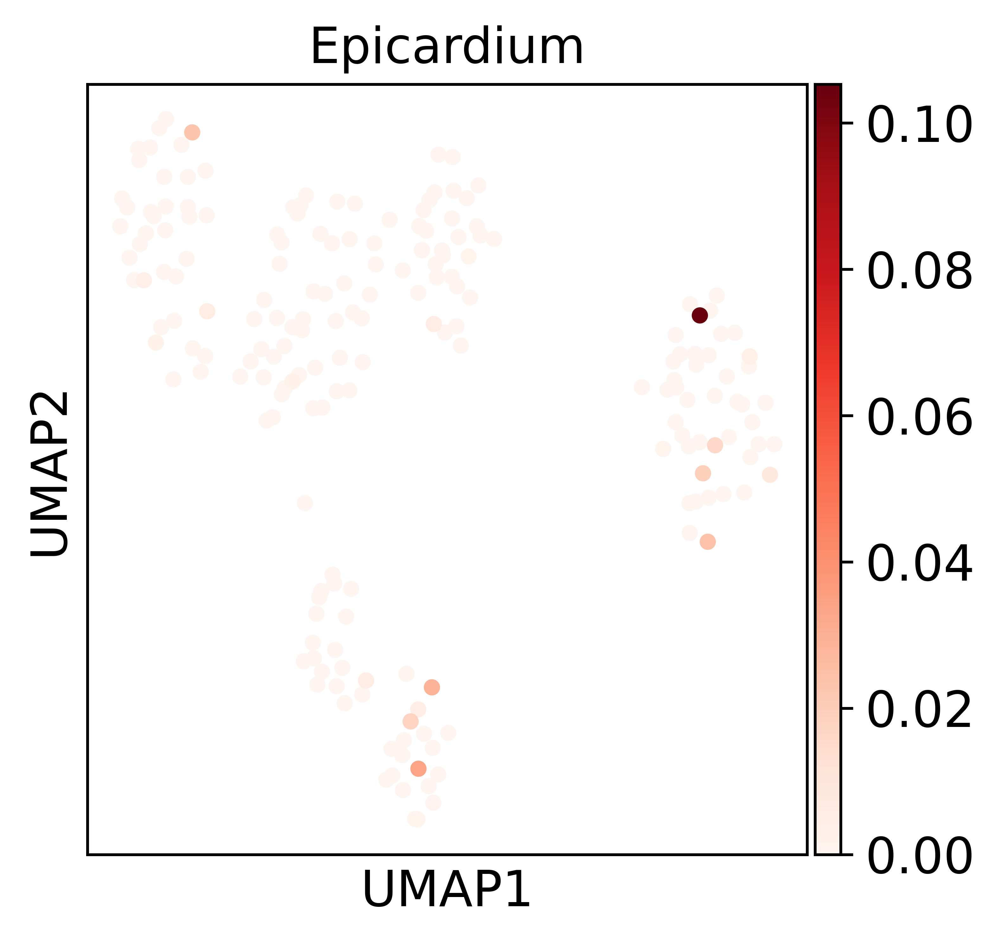

...

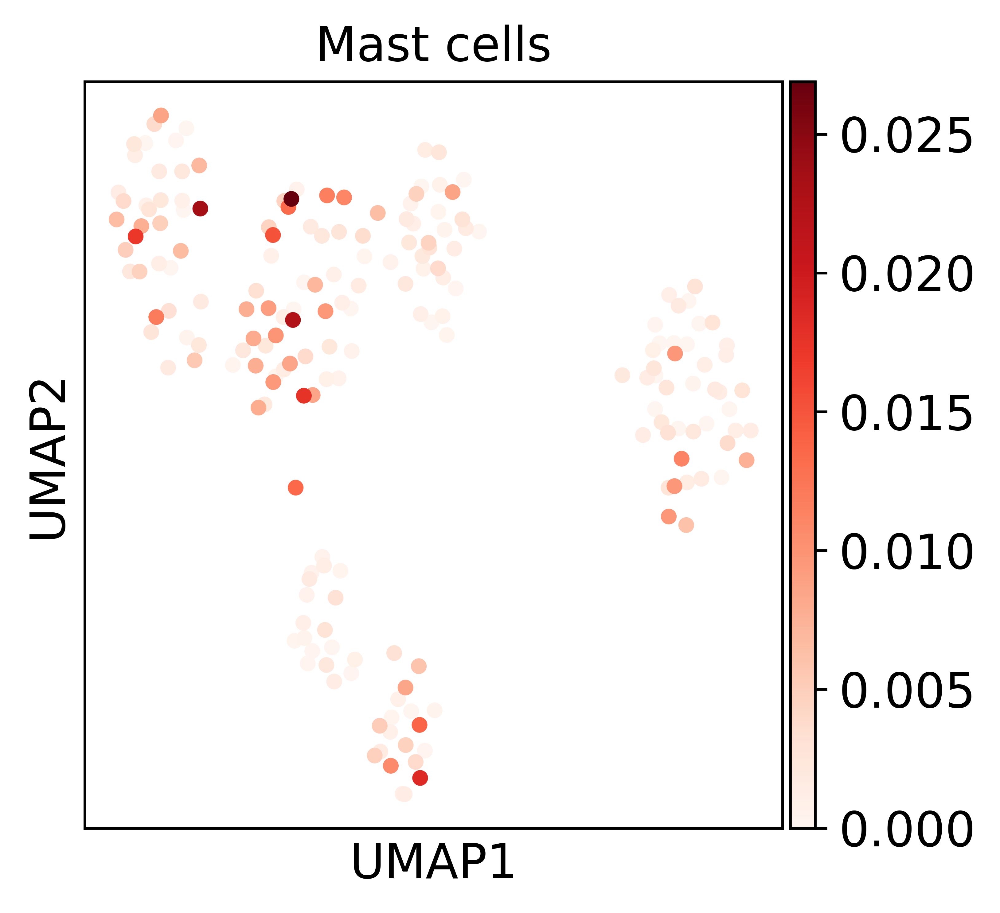

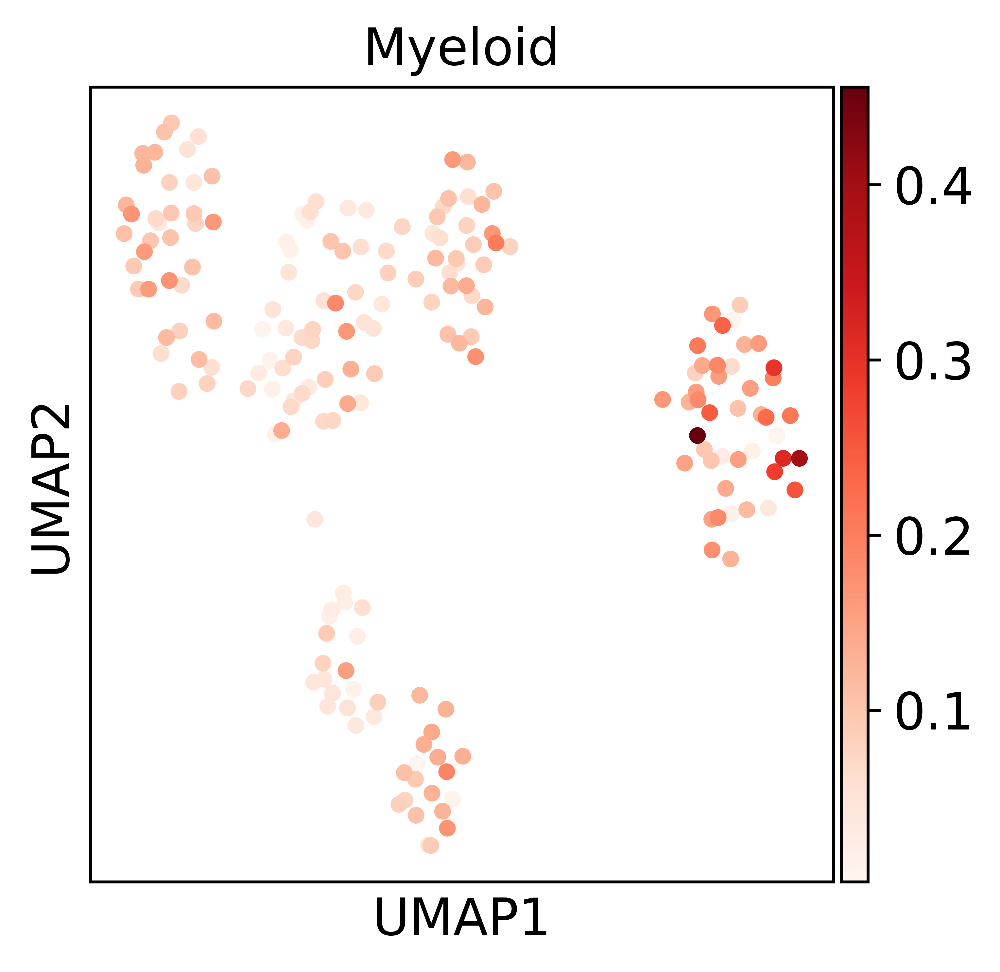

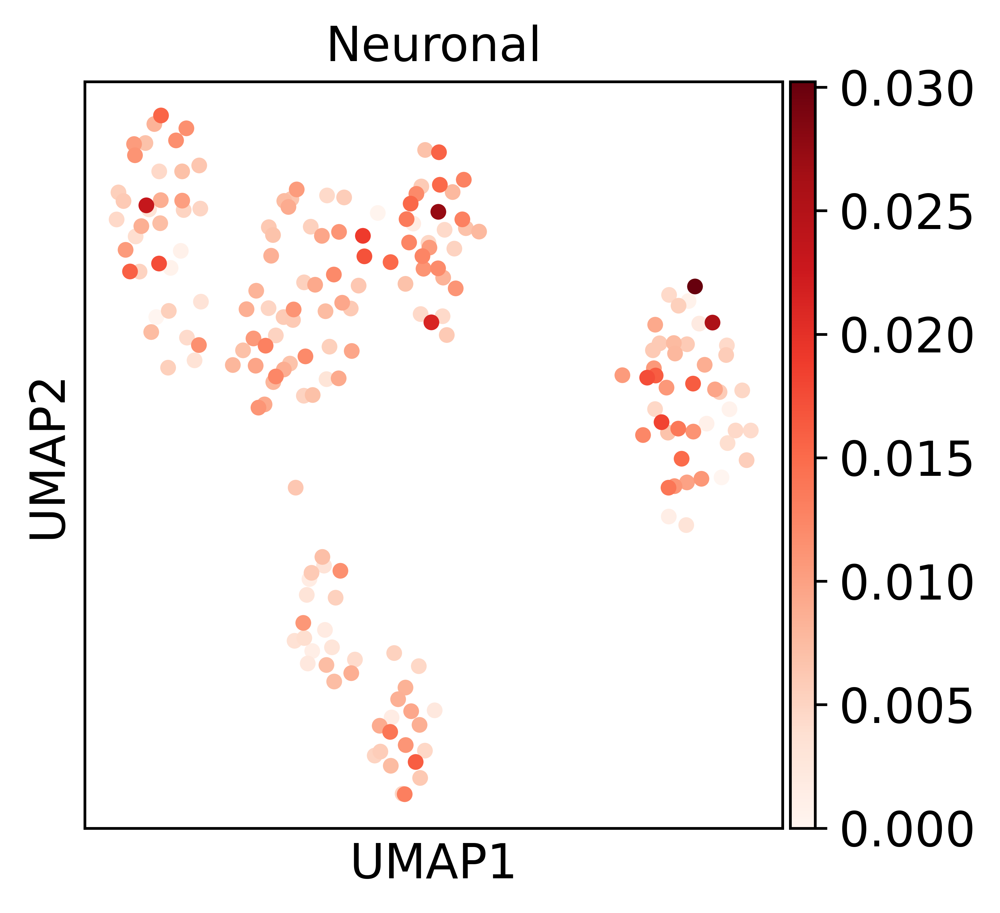

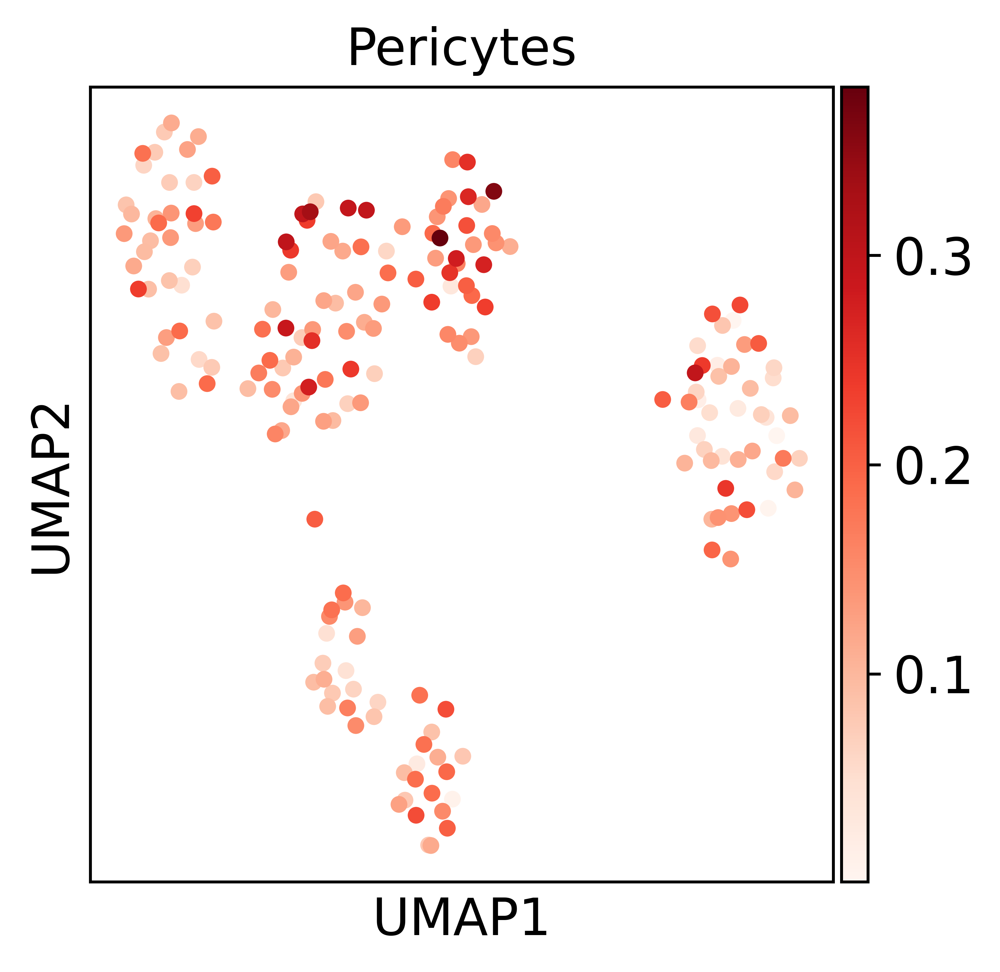

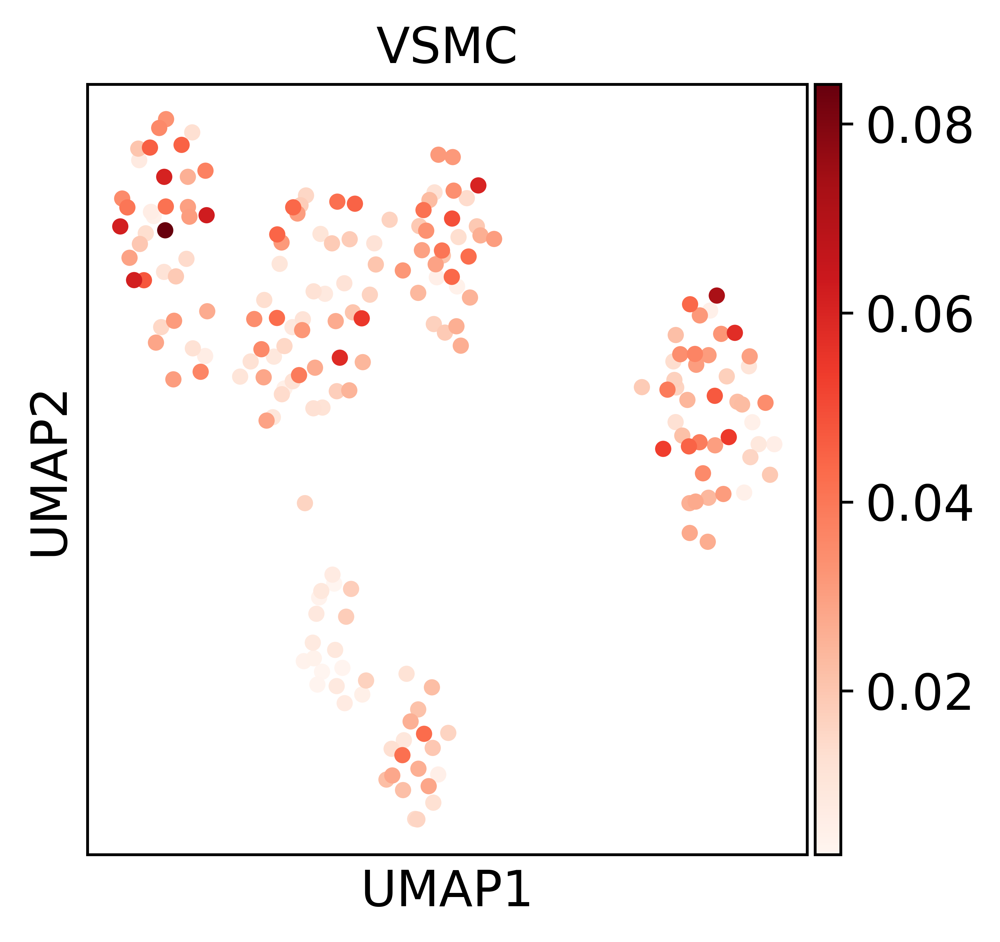

In [12]:
adata.obs["Myeloid"] = adata.obs["Monocytes"]
cells = ['Adipocytes',
 'Cardiomyocytes',
 'Endocardial',
 'Endothelial',
 'Epicardium',
 'Fibroblast',
 'Ischemic cells (MI)',
 'Lymphatic EC',
 'Lymphocytes',
 'Mast cells',
 'Myeloid',
 'Neuronal',
 'Pericytes',
 'VSMC',]

sc.set_figure_params(scanpy=True, dpi=400)#, #dpi_save=4000)
for cell in cells:
    sc.pl.umap(adata, color=[cell], size=85, cmap="Reds")

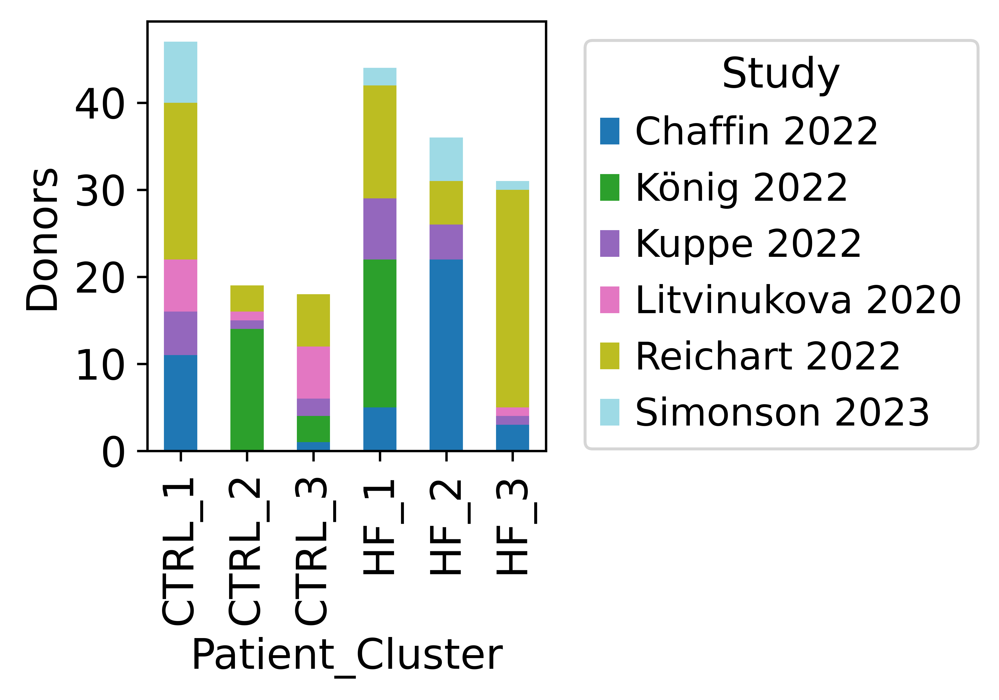

In [13]:
df = adata.obs
coloring = "Study"

region_counts = df.groupby(["Patient_Cluster", coloring]).size().unstack(fill_value=0)
region_percentages = region_counts.div(region_counts.sum(axis=1), axis=0) * 100

# Plot by Region
fig2, ax = plt.subplots(figsize=(5, 3.5))
#region_percentages.plot(kind="bar", stacked=True, ax=ax, colormap="tab20b")
region_counts.plot(kind="bar", stacked=True, ax=ax, colormap="tab20")

ax.set_ylabel("Donors")
ax.legend(title=coloring, bbox_to_anchor=(1.05, 1), loc='upper left')
ax = plt.gca()
ax = plt.gca()
#for side in ["top", "right", "bottom", "left"]:
#    ax.spines[side].set_visible(False)
#ax.tick_params(left=True, bottom=True)

ax.grid(False)
plt.tight_layout()

plt.show()

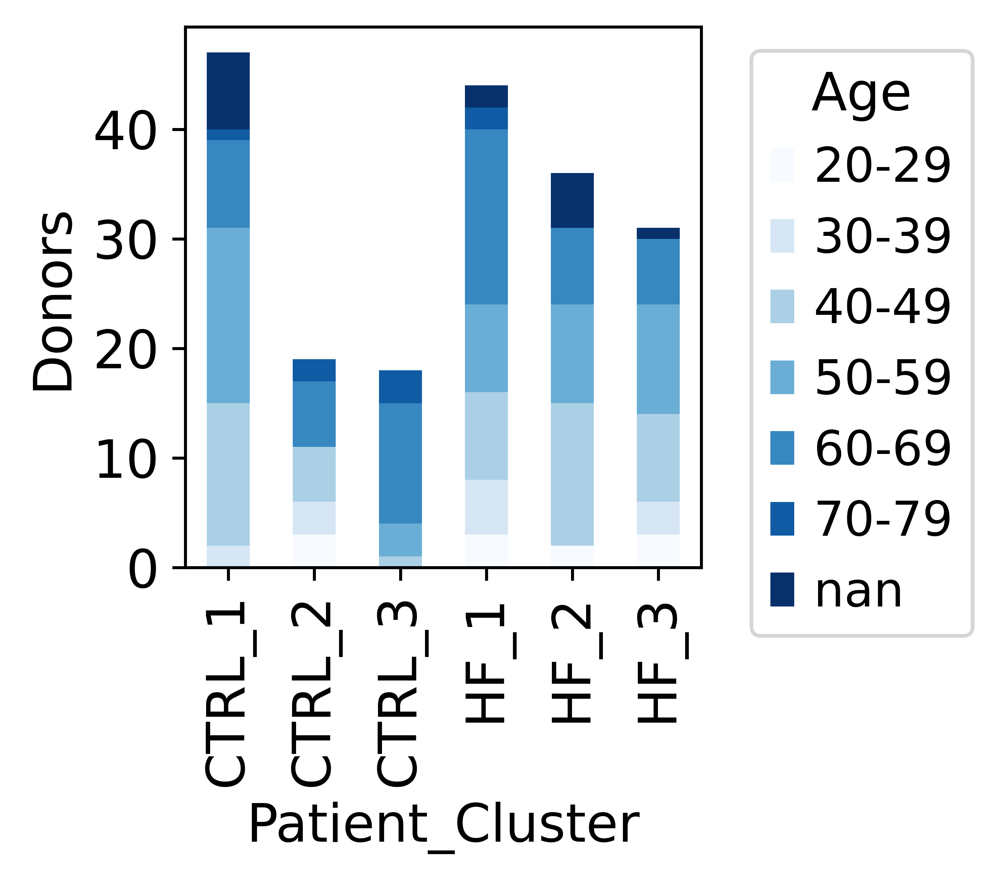

In [14]:
df = adata.obs
coloring = "Age"

region_counts = df.groupby(["Patient_Cluster", coloring]).size().unstack(fill_value=0)
region_percentages = region_counts.div(region_counts.sum(axis=1), axis=0) * 100

# Plot by Region
fig2, ax = plt.subplots(figsize=(4, 3.5))
#region_percentages.plot(kind="bar", stacked=True, ax=ax, colormap="tab20b")
region_counts.plot(kind="bar", stacked=True, ax=ax, colormap="Blues")

ax.set_ylabel("Donors")
ax.legend(title=coloring, bbox_to_anchor=(1.05, 1), loc='upper left')
ax = plt.gca()
ax = plt.gca()
#for side in ["top", "right", "bottom", "left"]:
#    ax.spines[side].set_visible(False)
#ax.tick_params(left=True, bottom=True)

ax.grid(False)
plt.tight_layout()

plt.show()

/w0/tmp/slurm_uv525372.57037038/ipykernel_178908/2726924172.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


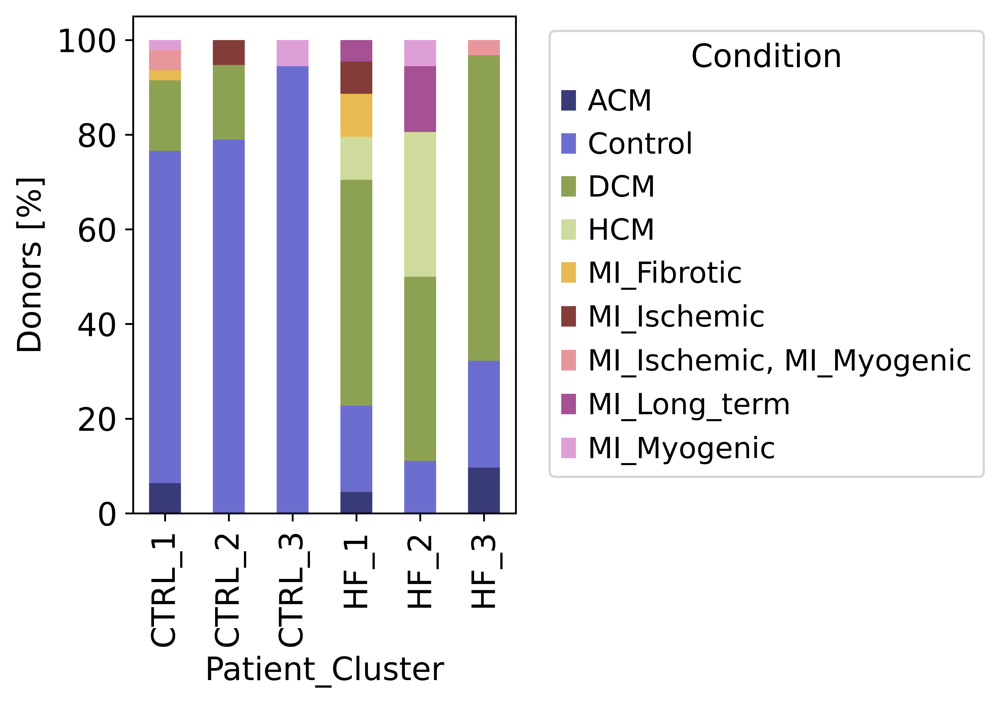

In [15]:
df = adata.obs
coloring = "Condition"

region_counts = df.groupby(["Patient_Cluster", coloring]).size().unstack(fill_value=0)
region_percentages = region_counts.div(region_counts.sum(axis=1), axis=0) * 100

# Plot by Region
fig2, ax = plt.subplots(figsize=(3, 4))
region_percentages.plot(kind="bar", stacked=True, ax=ax, colormap="tab20b")
#region_counts.plot(kind="bar", stacked=True, ax=ax, colormap="tab10")

ax.set_ylabel("Donors [%]")
ax.legend(title=coloring, bbox_to_anchor=(1.05, 1), loc='upper left')
ax = plt.gca()
ax = plt.gca()
#for side in ["top", "right", "bottom", "left"]:
#    ax.spines[side].set_visible(False)
#ax.tick_params(left=True, bottom=True)

ax.grid(False)
plt.tight_layout()

plt.show()

/w0/tmp/slurm_uv525372.57037038/ipykernel_178908/3384050004.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  set1 = plt.cm.get_cmap("Paired", 9)


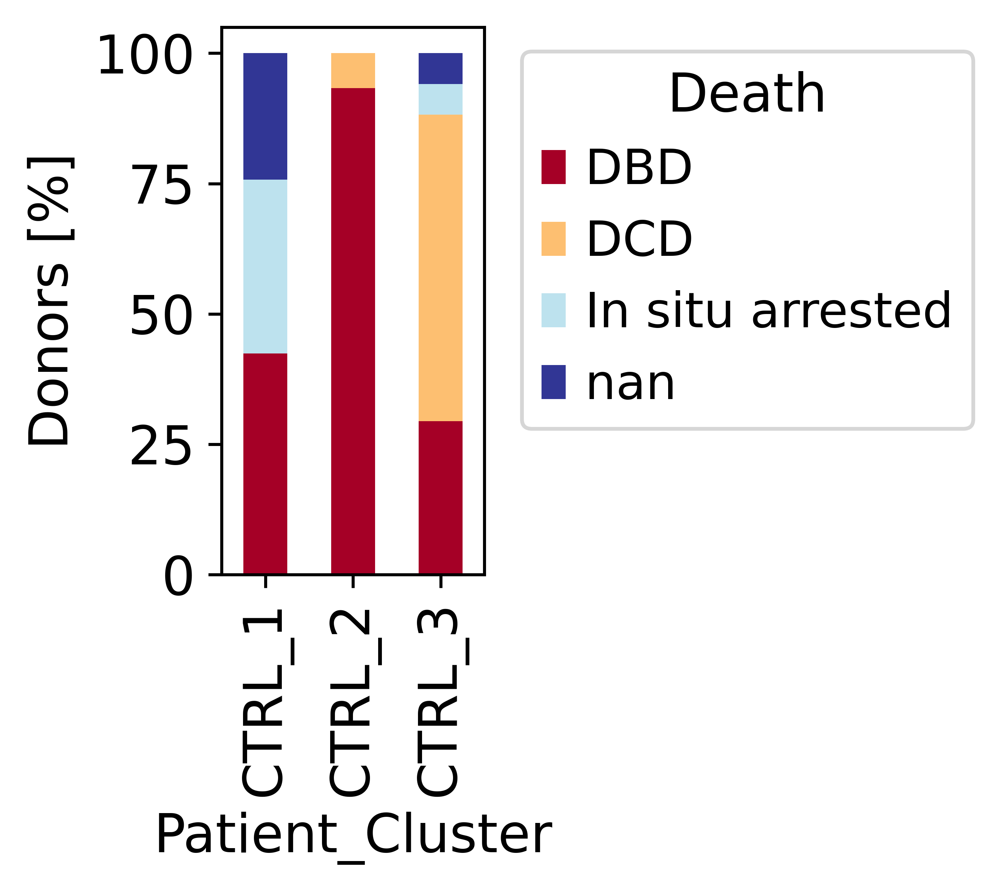

In [17]:
tmp = adata[(adata.obs["Condition"].isin(['Control',]))]
tmp = tmp[(tmp.obs["Patient_Cluster"].isin(['CTRL_1', 'CTRL_2', 'CTRL_3',]))]
df = tmp.obs
coloring = "Death"

set1 = plt.cm.get_cmap("Paired", 9)
colors = [set1(i) for i in [0, 0, 1, 0, 2, 0, 6]]
custom_cmap = mcolors.ListedColormap(colors)


region_counts = df.groupby(["Patient_Cluster", coloring]).size().unstack(fill_value=0)
region_percentages = region_counts.div(region_counts.sum(axis=1), axis=0) * 100

# Plot by Region
fig2, ax = plt.subplots(figsize=(4, 3.5))
region_percentages.plot(kind="bar", stacked=True, ax=ax, colormap="RdYlBu")
#region_counts.plot(kind="bar", stacked=True, ax=ax, colormap=custom_cmap)

ax.set_ylabel("Donors [%]")
ax.legend(title=coloring, bbox_to_anchor=(1.05, 1), loc='upper left')
ax = plt.gca()
ax = plt.gca()
#for side in ["top", "right", "bottom", "left"]:
#    ax.spines[side].set_visible(False)
#ax.tick_params(left=True, bottom=True)

ax.grid(False)
plt.tight_layout()

plt.show()

In [23]:
adata.obs.to_csv("/work/uv525372/heart_atlas/PanPy_analysis/Heart_atlas_Patient_Clustering.csv")

In [116]:
subset = adata[~(adata.obs["Study"].isin(['Kuppe 2022', 'Litvinukova 2020', 'Simonson 2023',]))]
subset = subset[(subset.obs["Condition"].isin(['DCM']))]
subset = subset[~(subset.obs["Genotype"].isin(['nan']))]

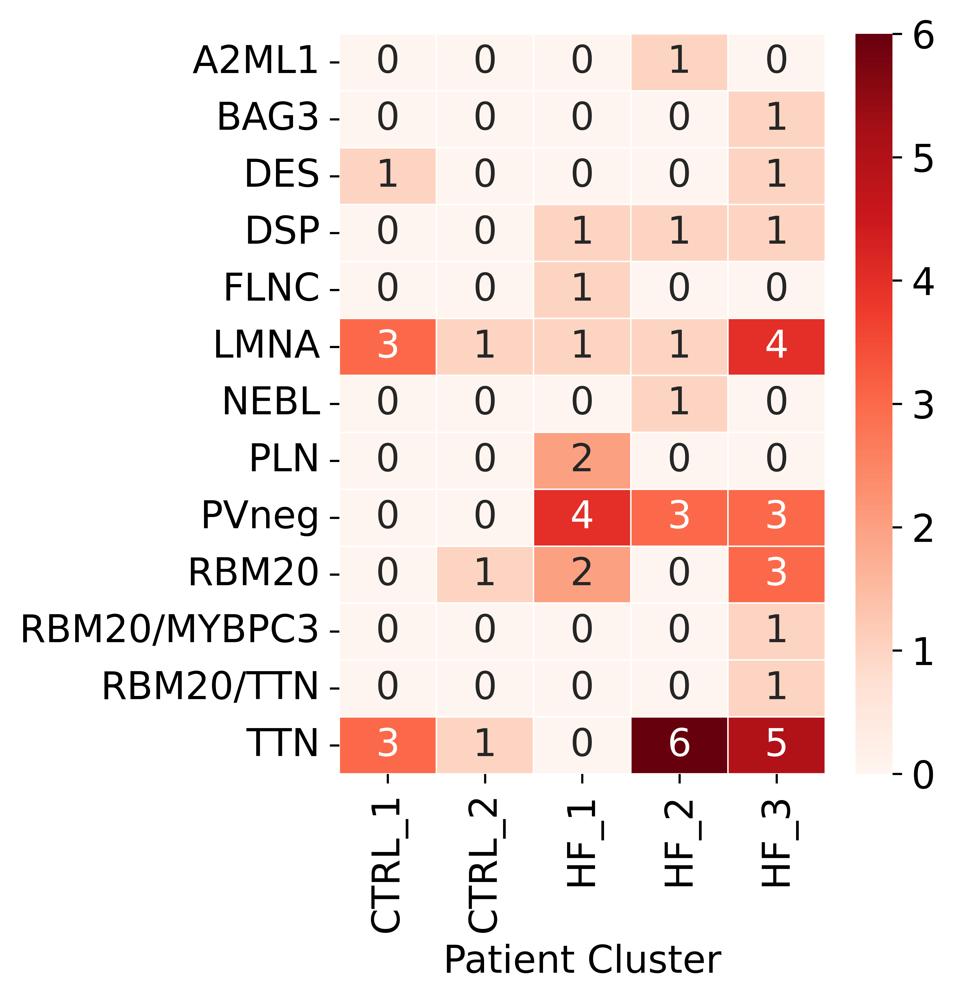

In [117]:
plot_tile(subset, "Patient_Cluster", ["Genotype"])

In [25]:
adata = sc.read_h5ad("/rwthfs/rz/cluster/hpcwork/noco0013/projects/novo_postdoc/data/Heart_Donor_mean_Subclustering.h5ad")

In [26]:
adata = adata[~adata.obs["Age"].isin(['0-9', '10-19']), :]

In [27]:
meta = pd.read_csv("/work/uv525372/heart_atlas/PanPy_analysis/Heart_atlas_Patient_Clustering.csv")

In [28]:
meta = meta.drop(columns=meta.loc[:, 'Tissue':'leiden'], errors='ignore')

In [29]:
adata.obs = adata.obs.join(meta.set_index('Donor'), on='Donor', how='left')

In [30]:
subset = adata[(adata.obs["Condition"].isin(['DCM', "Control"]))]

cells = subset.obs.columns.tolist()
start_index = cells.index("Adipocytes #1")
end_index = cells.index("VSMC (SULF1)")
cells_adata = subset.obs.iloc[:, start_index:end_index+1]
t = sc.AnnData(cells_adata, subset.obs.iloc[:, list(range(start_index)) + list(range(end_index + 1, subset.obs.shape[1]))])

In [31]:
Subcluster = {"Adipocytes" : ["Adipocytes #1", "Adipocytes #2",],
              "Cardiomyocytes" : ['Cardiomyocytes #1', 'Cardiomyocytes #2', 'Cardiomyocytes (LINGO1)', 'Cardiomyocytes (NPPA/NPPB)', 'Cardiomyocytes (THBS1)',],
              "Endocardial" : ['Endocardial (NRG1)','Endocardial (NRG3)', 'Endocardial EC',],
              "Endothelial" : ['EC, Angiogenic', 'EC, Aterial', 'EC, Capilllary','EC, IFN', 'EC, Proliferation', 'EC, Venous',],
              "Fibroblast" : ['Fibroblast (ABCA9, ACSM1)', 'Fibroblast (APOD/E)', 'Fibroblast (COL15A1, C7)', 'Fibroblast (PCOLCE2,SCARA5)', 'Fibroblast, Activated (FAP POSTN)','Fibroblast, Perivascular (PLA2G2A, THBS1)','Myofibroblast (ACTA2, SMAD6)','Myofibroblast, pro-inflammtory (FAP,CCL2)',],
              'Lymphatic EC': ['Lymphatic EC'],
              "Lymphocytes" : ['B cells','Megakaryocyte','Natural Killer (GLNY)','Natural Killer (KLRC1)', 'Plasma cells', 'Plasma cells / NK (GZMB, ACM)', 'Proliferating Lymphocytes', 'T cells (CD4, CD40LG)', 'T cells (CD8, CCL5)', 'T cells, regulatory (FOXP3)',],
              'Mast cells' : ["Mast cells"],
              "Myleoid" : ['Dendritic cells', 'Macrophage #1', 'Macrophage #2', 'Macrophage #3', 'Macrophages (SPP1)', 'Monocytes (CD14)', 'Monocytes (CD16)', 'Monocytes, Proliferating',],
              "Neural" : ['Neuronal'],
              "Pericytes" : ['Pericytes (ACTB)', 'Pericytes (APOD)',],
              "VSMC": ["VSMC (DSCAML1)", "VSMC (LGR6)", "VSMC (SULF1)",]}

In [51]:
value_counts = t.obs['Cluster_Condition'].value_counts()
reference = t[t.obs['Cluster_Condition'].isin(value_counts.index[value_counts > 10])]

In [81]:
sc.pl.dotplot(reference, Subcluster, 'Patient_Cluster', standard_scale="var", cmap="Reds", dendrogram=False)

/home/uv525372/miniconda3/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


In [50]:
cells_adata = cells_adata.rename(columns={"Cardiomyocytes (LINGO1)": "aberrant cardiomyocytes", "Fibroblast (APOD/E)": "aberrant fibroblast"})
t = sc.AnnData(cells_adata, subset.obs.iloc[:, list(range(start_index)) + list(range(end_index + 1, subset.obs.shape[1]))])

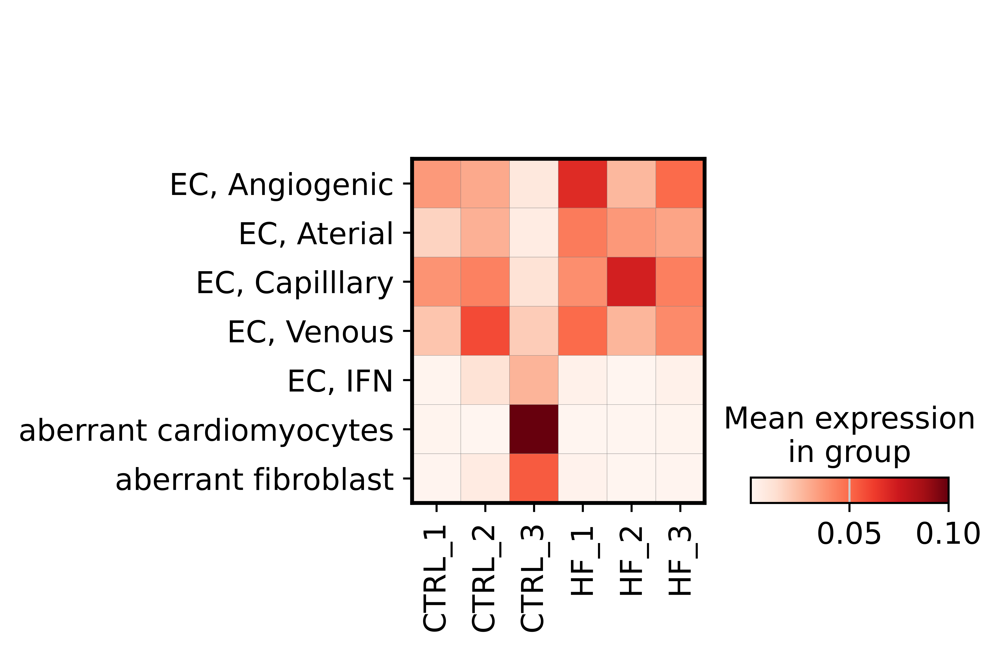

In [56]:
sc.pl.matrixplot(reference, ['EC, Angiogenic', 'EC, Aterial', 'EC, Capilllary', 'EC, Venous', 'EC, IFN', 'aberrant cardiomyocytes', 'aberrant fibroblast'], 'Patient_Cluster', cmap="Reds", vmax=0.1, swap_axes=True,dendrogram=False)